# Part 5 - Portfolio Analytics

**Summary.** MSCI USA Value delivers strong HML exposure (+0.322; t = 19.7), but no statistically significant alpha (t = -0.91). A fitted Fama-French replication shows a higher historical Sharpe (0.529 versus 0.450), subject to trading costs and in-sample bias. The multi-factor index has a weak benchmark-relative information ratio (0.045). Minimum Volatility has the strongest stand-alone Sharpe (0.66) but meaningful benchmark-relative risk.


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'pyproject.toml').exists():
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
sys.path.insert(0,str(ROOT/'src'))
from part5.analysis import load_sample, analyze, fit_factors, save_charts, OUT
OUT.mkdir(parents=True,exist_ok=True)
data=load_sample()
result, returns, active = analyze(data)
save_charts(returns,active,result)
print(f"Sample: {result['n']} months; {result['start']} to {result['end']}")

Sample: 343 months; 1995-01 to 2023-07


## 5A. MSCI Value and Fama-French value definitions

MSCI uses three value indicators: book value/price, 12-month forward earnings/price, and dividend yield. It separately measures growth using long- and short-term forward EPS growth, current internal growth, historical long-term EPS growth, and historical long-term sales-per-share growth. Value and growth membership can overlap, with partial style weights. MSCI's exceptions apply **only to growth variables** and are set by GICS industry and by size segment: long-term historical sales-per-share growth is not used for Banks and Diversified Financials (except Multi-Sector Holdings and Financial Exchanges & Data), and long-term forward EPS growth is not used for small-cap indexes. In those cases the remaining growth variables are averaged.

Fama-French HML instead uses **one cheapness measure, book-to-market (B/M)**. Stocks are sorted into a 2-by-3 grid by size (small/big) and B/M (low/neutral/high), rebalanced each June. HML is the average return of high-B/M portfolios minus low-B/M portfolios across the two size groups. The low-B/M end represents growth without MSCI's separate five-signal growth score.

| Design choice | MSCI USA Value | Fama-French HML |
|---|---|---|
| Value signal | Book/price, 12-month forward earnings/price, dividend yield | Single book-to-market ratio |
| Growth treatment | Separate five-indicator score | Low book-to-market end of sort |
| Construction | Long-only large/mid-cap style weights | Long-short 2x3 size/B/M sorts; June rebalance |
| Implication | Investable but blends style and universe decisions | Pure value spread; long/short, not directly investable |

**Exhibit 5A.** Value methodology comparison, US equity universe (MSCI USA Standard; Fama-French US factor portfolios). Sources: MSCI Global Investable Market Value and Growth Index Methodology (February 2021); Kenneth R. French Data Library, factor definitions.


In [2]:
display(pd.DataFrame({'MSCI Value':['Three value signals','Five separate growth indicators','Long-only style index'],'FF HML':['One book-to-market signal','Low B/M denotes growth','Long-short 2x3 factor spread']},index=['Value','Growth','Implementation']))

,MSCI Value,FF HML
Value,Three value signals,One book-to-market signal
Growth,Five separate growth indicators,Low B/M denotes growth
Implementation,Long-only style index,Long-short 2x3 factor spread


## 5B. Factor exposure regression

Using 343 monthly gross USD returns (January 1995-July 2023), we regress MSCI USA Value on an intercept, RF, market excess return, HML and SMB. Coefficients measure exposure; conventional OLS t-statistics measure estimation precision.

| Regressor | Loading | t-statistic | Interpretation |
|---|---:|---:|---|
| Intercept (monthly %) | -0.0713 | -0.91 | No significant positive alpha |
| RF | 0.8646 | 2.79 | Cash-rate exposure estimated, not fixed |
| Market excess | 0.9480 | 76.99 | Near-market equity sensitivity |
| HML | +0.3216 | 19.68 | Strong value exposure |
| SMB | -0.1744 | -9.90 | Large-cap bias embedded in style index |

**Exhibit 5B.** OLS factor fingerprint of MSCI USA Value, January 1995-July 2023, 343 monthly observations, MSCI USA Standard and Fama-French US factors. Source: supplied MSCI and Fama-French workbook.

R-squared is **94.84%**. In a month when HML gains one percentage point, the fitted index return increases by 0.322 percentage points, holding other inputs fixed; a one-point SMB gain reduces it by 0.174 points. Thus MSCI Value is not pure HML: its large-cap tilt creates a distinct performance headwind when small caps outperform. **Verdict:** MSCI Value behaves as advertised: strong value exposure (HML +0.32; t = 19.7) alongside a large-cap tilt (SMB -0.17; t = -9.9). The intercept does not establish additional alpha.


In [3]:
model=fit_factors(data)
display(pd.DataFrame({'Loading':model.params,'t-statistic':model.tvalues,'p-value':model.pvalues}).round(4))
print('R-squared:',round(model.rsquared,4))

,Loading,t-statistic,p-value
const,-0.0713,-0.9058,0.3657
RF,0.8646,2.7885,0.0056
Mkt-RF,0.9480,76.9858,0.0000
HML,0.3216,19.6816,0.0000
SMB,-0.1744,-9.9046,0.0000


R-squared: 0.9484


## 5C. Does the methodology enhance results

The monthly intercept is **-0.0713%** (t = -0.91; p = 0.366), approximately -0.86% a year by simple annualization. There is therefore no statistically significant alpha beyond the fitted factors; the point estimate is negative. After the **May 2003 methodology change**, the June 2003-July 2023 subsample gives an intercept of **-0.0378% a month (t = -0.55; n = 242)**, which supports the same conclusion.

| Sample | Intercept (monthly %) | t-statistic | Months |
|---|---:|---:|---:|
| Jan 1995-Jul 2023 | -0.0713 | -0.91 | 343 |
| Jun 2003-Jul 2023 | -0.0378 | -0.55 | 242 |

**Exhibit 5C.** Intercept of MSCI USA Value on RF, Mkt-RF, HML and SMB, full sample and after the May 2003 methodology change, gross USD. Source: supplied workbook; authors' OLS calculations.


In [4]:
post=fit_factors(data.loc['2003-06':])
display(pd.DataFrame({'Period':['Full sample','Post-May-2003'],'Monthly alpha (%)':[model.params['const'],post.params['const']],'t-statistic':[model.tvalues['const'],post.tvalues['const']]}).round(4))

,Period,Monthly alpha (%),t-statistic
0,Full sample,-0.0713,-0.9058
1,Post-May-2003,-0.0378,-0.5508


## 5D. Fund replication

The fitted zero-alpha replica is 0.8646 RF + 0.9480 (Mkt-RF) + 0.3216 HML - 0.1744 SMB. Replication was effective in sample (correlation **0.974**), but the apparent performance advantage is not a tradeable, out-of-sample result.

| Metric | MSCI Value | FF replication |
|---|---:|---:|
| Arithmetic return, annualized | 9.87% | 10.73% |
| CAGR | 9.05% | 10.05% |
| Volatility, annualized | 15.27% | 14.87% |
| Geometric Sharpe | 0.450 | 0.529 |

**Exhibit 5D.1.** Return, risk and Sharpe ratio of MSCI USA Value and the fitted Fama-French replication, January 1995-July 2023, gross USD, in sample. Sharpe = (CAGR - compounded RF) / annualized volatility. Source: supplied workbook; authors' calculations.

![Exhibit 5D.2: Growth of $1](5d_replication_growth.png)

**Exhibit 5D.2.** Growth of $1, MSCI USA Value versus fitted Fama-French replication, January 1995-July 2023, gross USD, in sample. Source: supplied workbook; authors' calculations.

Before implementation, check shorting availability and trading/financing costs for long-short factors, replication fees versus a low-cost index fund, and the risk of in-sample coefficient fitting. The 0.86 percentage-point arithmetic return gap mirrors the insignificant -0.86% a year fitted intercept.


,arithmetic_ann,geometric_ann,vol_ann,sharpe
Value,9.874,9.049,15.267,0.450
Replication,10.729,10.046,14.868,0.529


Replication correlation: 0.974


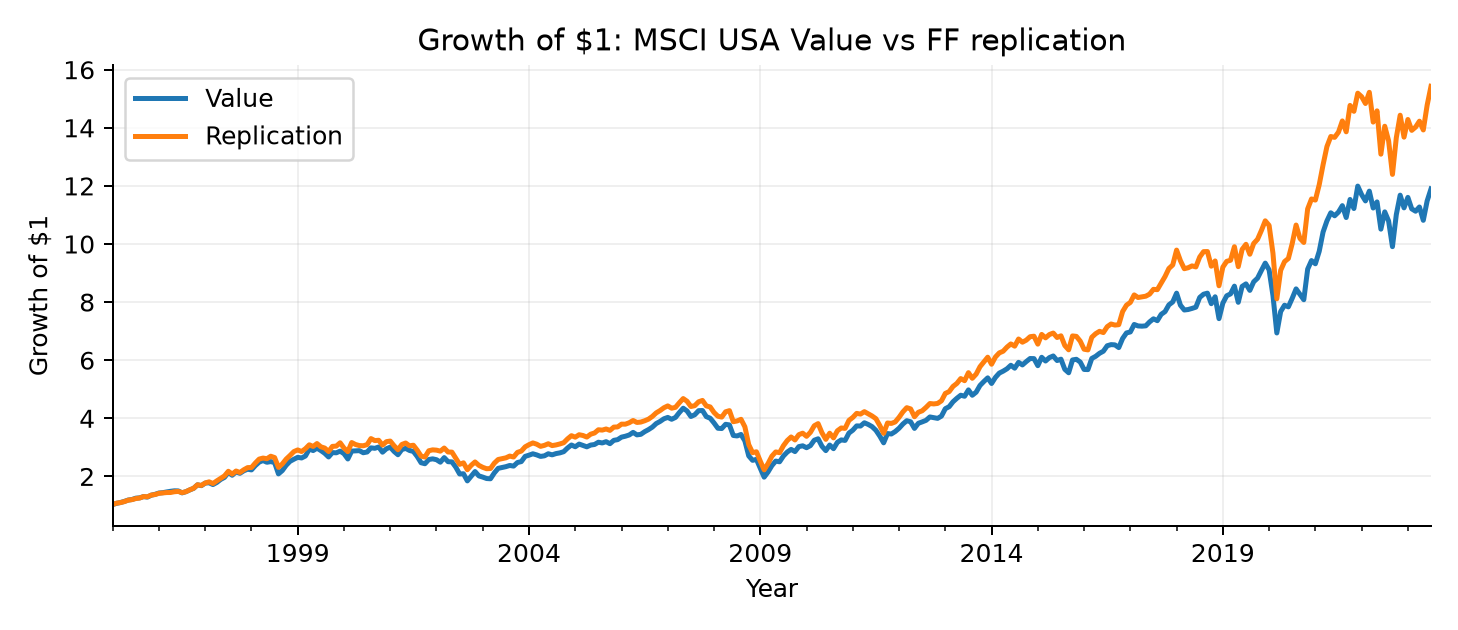

In [5]:
display(pd.DataFrame(result['portfolios']).T.round(3))
print('Replication correlation:',round(result['replication_correlation'],3))
display(Image(filename=str(OUT/'5d_replication_growth.png')))

## 5E. Benchmark relative performance

Active return is each index's monthly return less MSCI USA Standard; the multi-factor index equally weights four styles and rebalances monthly. Tracking error is the annualized standard deviation of monthly active returns (monthly standard deviation x sqrt(12)); the information ratio (IR) is annualized arithmetic active return divided by tracking error.

| Index | Active return (annual) | Tracking error | IR |
|---|---:|---:|---:|
| Value | -1.34% | 5.15% | -0.261 |
| Minimum Volatility | -0.80% | 6.38% | -0.125 |
| Equal Weight | +0.59% | 5.40% | 0.109 |
| Momentum | +2.16% | 7.73% | 0.279 |
| Multi-factor index | +0.15% | 3.39% | **0.045** |

**Exhibit 5E.1.** Annualized active return, tracking error and information ratio versus MSCI USA Standard, January 1995-July 2023, gross USD; MSCI USA Value, Minimum Volatility, Equal Weighted, Momentum and the multi-factor index. Source: supplied MSCI index data; authors' calculations.

The multi-factor index's IR of 0.045 indicates little active return per unit of benchmark-relative risk. Its 0.15% arithmetic active return and 0.34 percentage-point geometric CAGR advantage measure different quantities. As Part 1 found, the index nevertheless beat the market on Sharpe (0.60 versus 0.54), primarily because of lower volatility.

![Exhibit 5E.2: Cumulative active return](5e_active_returns.png)

**Exhibit 5E.2.** Cumulative arithmetic active return versus MSCI USA Standard, January 1995-July 2023, gross USD; "MultiFactor" in the legend is the multi-factor index. Source: supplied MSCI index data; authors' calculations.


,annual_excess,tracking_error,information_ratio
Value,-1.343,5.154,-0.261
MinVol,-0.796,6.380,-0.125
EqualWeight,0.588,5.396,0.109
Momentum,2.158,7.730,0.279
MultiFactor,0.152,3.387,0.045


Geometric CAGR spread (percentage points): 0.336


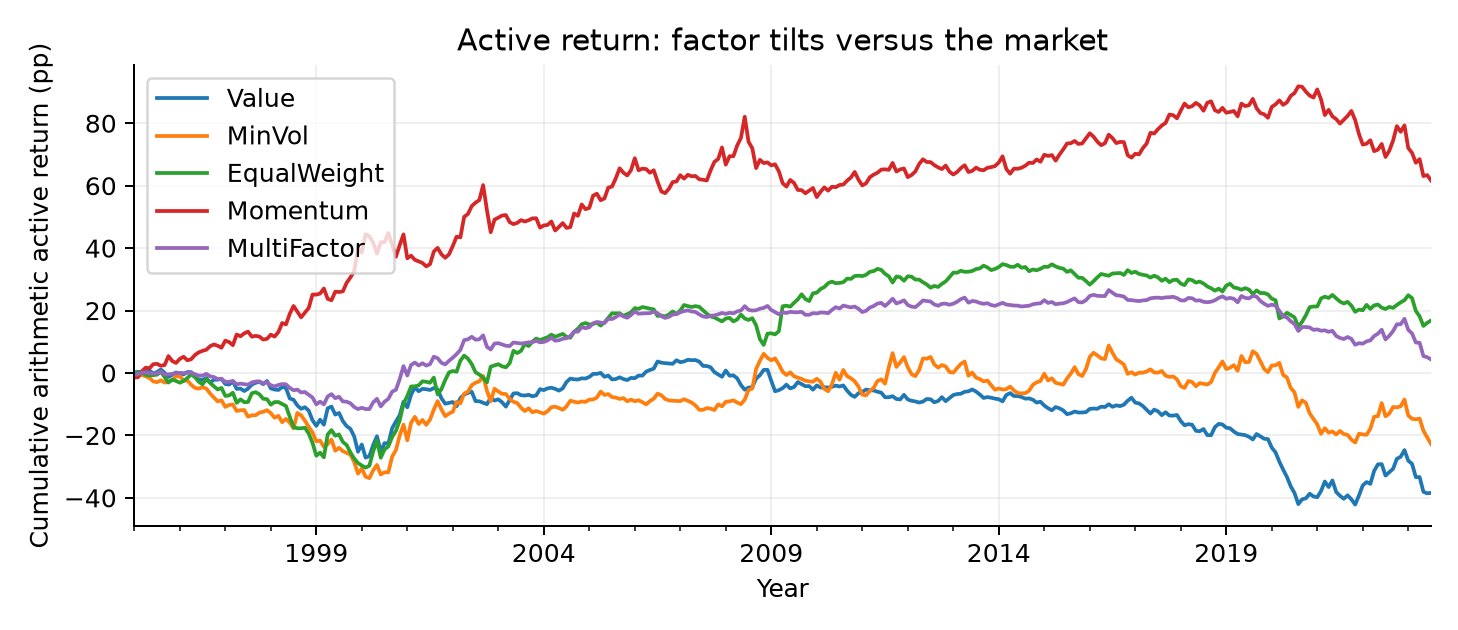

In [6]:
display(pd.DataFrame(result['active']).T.round(3))
print('Geometric CAGR spread (percentage points):',round(result['geometric_active_spread'],3))
display(Image(filename=str(OUT/'5e_active_returns.png')))

## 5F. Active risk decomposition and investment decision

Exhibit 5F splits the multi-factor index's active-return variance across the four indexes. With equal-weight active returns a_i and index active return a_p = (1/4) sum_i a_i, each index's share is Cov(a_i, a_p) / [4 Var(a_p)], and the shares sum to 100%.

| Factor | Share of active-return variance |
|---|---:|
| Value | 23.26% |
| Minimum Volatility | 34.08% |
| Equal Weight | 17.86% |
| Momentum | 24.81% |

**Exhibit 5F.** Covariance contributions to multi-factor index active-return variance, January 1995-July 2023, MSCI USA smart-beta indexes relative to MSCI USA Standard, gross USD. Source: supplied MSCI index data; authors' calculations.

Minimum Volatility is the largest active-risk driver at 34.08%, despite equal portfolio weights.

![Exhibit 5F.2: Active-risk contributions](5f_tracking_error_decomposition.png)

**Exhibit 5F.2.** Share of multi-factor index active-return variance by index, January 1995-July 2023, gross USD. Source: supplied MSCI index data; authors' calculations.

**Decision:** Minimum Volatility is the preferred stand-alone risk-adjusted investment (Sharpe 0.66), but its IR of -0.125, tracking error of 6.38%, and market beta near 0.72 make it harder to hold for benchmark-constrained managers during strong equity rallies. The multi-factor index is a defensible lower-volatility compromise, not a compelling source of active alpha.

**Methods and caveats.** Monthly gross USD observations cover January 1995-July 2023. OLS t-statistics are conventional, without autocorrelation adjustment. Factor replication is fitted and assessed in sample; implementation costs, shorting constraints, and fees are excluded.


,Variance contribution (%)
Value,23.26
MinVol,34.08
EqualWeight,17.86
Momentum,24.81


Minimum Volatility beta: 0.721


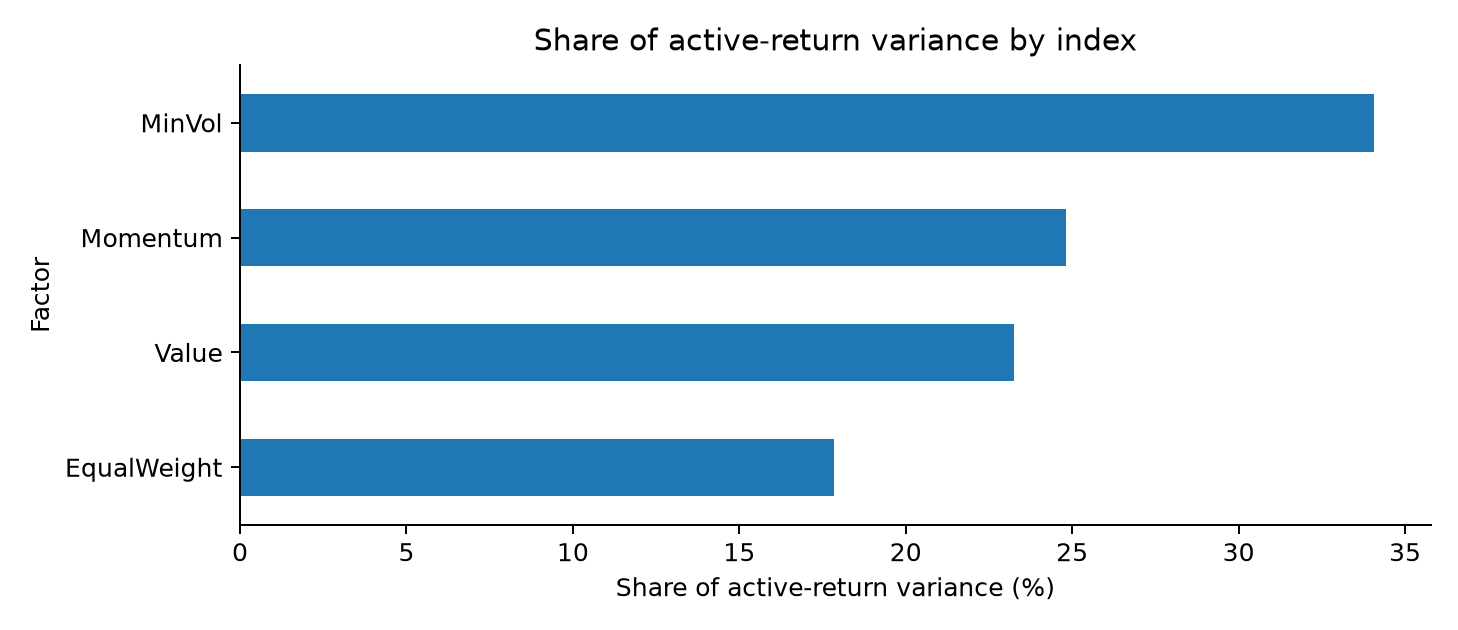

In [7]:
display(pd.Series(result['variance_contributions']).mul(100).to_frame('Variance contribution (%)').round(2))
print('Minimum Volatility beta:',round(result['minvol_beta'],3))
display(Image(filename=str(OUT/'5f_tracking_error_decomposition.png')))